In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
diabetes = load_diabetes()

X = diabetes.data
y = diabetes.target

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)
print("Feature names:", diabetes.feature_names)
print("First 10 target values:", y[:10])

Dataset shape: (442, 10)
Target shape: (442,)
Feature names: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
First 10 target values: [151.  75. 141. 206. 135.  97. 138.  63. 110. 310.]


In [3]:
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Target minimum:", y.min())
print("Target maximum:", y.max())

Number of samples: 442
Number of features: 10
Target minimum: 25.0
Target maximum: 346.0


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 353
Testing samples: 89


In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [6]:
svr_model = SVR(
    kernel="rbf",
    C=100,
    epsilon=5,
    gamma="scale"
)

svr_model.fit(X_train_scaled, y_train)

print("SVR model training completed.")

SVR model training completed.


In [7]:
y_pred = svr_model.predict(X_test_scaled)

print("Actual values:    ", y_test[:10])
print("Predicted values: ", np.round(y_pred[:10], 2))

Actual values:     [219.  70. 202. 230. 111.  84. 242. 272.  94.  96.]
Predicted values:  [129.7  180.25 179.71 221.99 107.86 120.62 271.58 202.81 107.54 107.59]


In [8]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Mean Absolute Error (MAE): 39.41
Mean Squared Error (MSE): 2597.32
Root Mean Squared Error (RMSE): 50.96
R2 Score: 0.5098


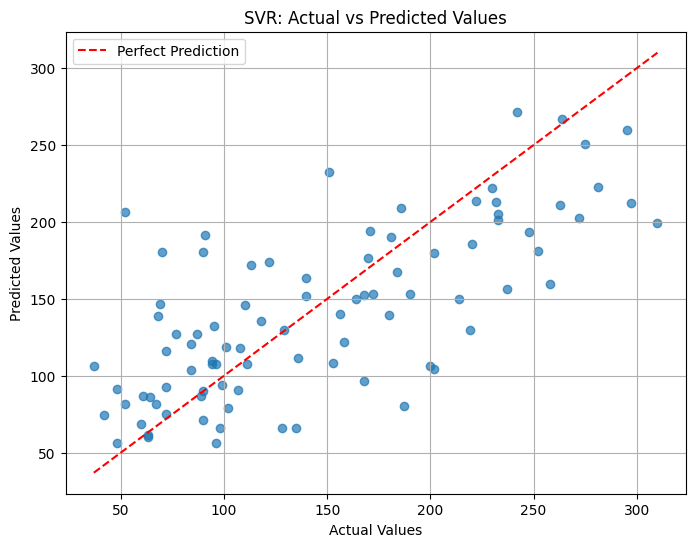

In [9]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("SVR: Actual vs Predicted Values")
plt.legend()
plt.grid(True)
plt.show()

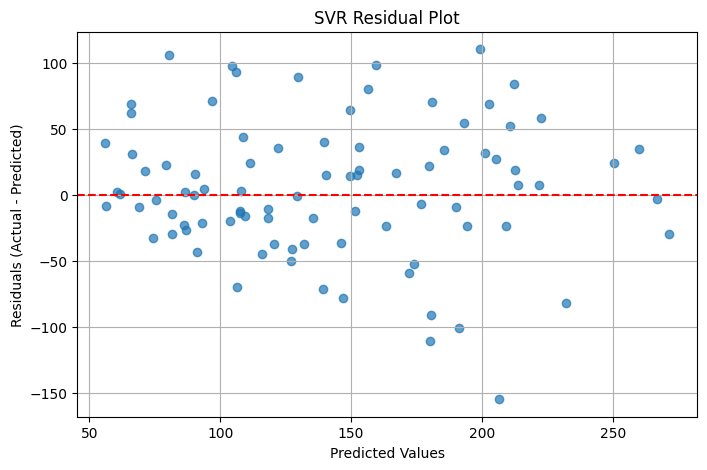

In [10]:
errors = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, errors, alpha=0.7)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Values")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("SVR Residual Plot")
plt.grid(True)
plt.show()